# Notebook 04 - Spectral Clustering

This notebook runs clustering on clean NIR and MIR spectra, selects K with the quantitative elbow method of Shi (2021), and reports spectral similarity metrics.

## Quick Start (for new users)

1. Ensure Notebook 03 finished successfully and generated `03_nir_pca_scores.csv` and `03_eda_metadata.json` in `Outputs/pipeline/`.
2. Run all cells in order.
3. Confirm outputs in `Outputs/pipeline/`: `04_k_selection_metrics.csv`, `04_cluster_assignments.csv`, `04_centroid_euclidean.csv`, `04_centroid_pearson.csv`, `04_clustering_metadata.json`, and `04_user_report.txt`.
4. Review figures in `Outputs/pipeline/Figures/`: `04_k_selection.png` and `04_cluster_pca_scatter.png`.
5. If upstream artifacts are missing, rerun Notebooks 02 and 03 using the same output folder before retrying.
6. If the notebook reports missing packages, run `launch_pipeline_vscode.bat` and reopen VS Code.

In [1]:
import importlib.util
import sys

RUNTIME_PACKAGES = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
    'scikit-learn': 'sklearn',
}

missing_packages = [pkg_name for pkg_name, module_name in RUNTIME_PACKAGES.items() if importlib.util.find_spec(module_name) is None]
if missing_packages:
    print('Missing dependencies detected:')
    for package_name in missing_packages:
        print(f'  - {package_name}')
    raise RuntimeError(
        'This notebook cannot continue because required packages are missing. '
        'Run launch_pipeline_vscode.bat from the repository root, reopen VS Code, and run this notebook again.'
    )

if '.venv' not in str(sys.executable).lower():
    print('Warning: active interpreter is not .venv. For non-technical users, run launch_pipeline_vscode.bat and reopen VS Code.')
else:
    print('Environment check passed: .venv interpreter detected and required packages are available.')

Environment check passed: .venv interpreter detected and required packages are available.


## Theoretical Framework

### Spectral segmentation of soil libraries

Unsupervised spectral clustering has two core purposes in this pipeline:

1. **Spectral-space description**: identify sample subpopulations with homogeneous spectral behavior (for example, oxidic vs clay-rich vs sandy soils) without using analytical labels.
2. **Modeling stratification**: each sample cluster is used in Notebook 05 as a grouping variable, enabling within-cluster prediction models that can outperform a single global model when spectral heterogeneity is high.

> **Dematte et al. (2022)** cite Viscarra Rossel et al. (2016), where segmenting a large Brazilian spectral library into homogeneous groups improved organic carbon and clay predictions compared to non-segmented models.

> **Dissertacao Ormeno** describes k-means over PCA scores in Planaltina data as a pre-calibration step for PLSR models of Cerrado soil properties.

**Sequence guard:** requires `02_nir_clean.csv`, `03_nir_pca_scores.csv`, and `03_eda_metadata.json`.

In [2]:
import time
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

ROOT = Path.cwd().resolve().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from spectral_pipeline_utils import get_spectral_columns, pca_svd, run_stamp, write_json

OUTPUT_SUBFOLDER = 'pipeline'
OUTPUT_DIR = ROOT / 'Outputs' / OUTPUT_SUBFOLDER
FIG_DIR = OUTPUT_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DOMAIN_CONFIG = {
    'nir': {
        'clean_path': OUTPUT_DIR / '02_nir_clean.csv',
        'pca_path': OUTPUT_DIR / '03_nir_pca_scores.csv',
    },
    'mir': {
        'clean_path': OUTPUT_DIR / '02_mir_clean.csv',
        'pca_path': OUTPUT_DIR / '03_mir_pca_scores.csv',
    },
}

required_files = [
    DOMAIN_CONFIG['nir']['clean_path'],
    DOMAIN_CONFIG['nir']['pca_path'],
    DOMAIN_CONFIG['mir']['clean_path'],
    DOMAIN_CONFIG['mir']['pca_path'],
    OUTPUT_DIR / '03_eda_metadata.json',
]
for file in required_files:
    if not file.exists():
        raise FileNotFoundError(
            f'Missing upstream artifact: {file}. Run Stage 03 first using the same output folder.'
        )

print('Stage 04 preflight passed: Stage 02/03 artifacts are available for NIR and MIR.')

Stage 04 preflight passed: Stage 02/03 artifacts are available for NIR and MIR.


## Block 1 - K-Means on PCA scores with Shi (2021) quantitative elbow selection

### Why run k-means on PCA scores instead of raw spectra?

Spectra contain hundreds or thousands of strongly correlated bands. Running k-means directly in that space has two major drawbacks:
- **Curse of dimensionality**: Euclidean distance loses discriminative power in very high dimensions.
- **Redundancy**: adjacent bands carry overlapping information, overweighting repeated structure.

Projecting first to the **first 6 PCs** (typically capturing most variance) compresses relevant information and reduces noise. K-means in this compact space is usually more stable and faster.

### Selecting the number of clusters K

The notebook tests K values from 2 to 10. For each K it computes inertia (sum of squared distances to centroids), then applies the Shi (2021) quantitative elbow method:
- Inertia is normalized across K.
- The curve geometry is evaluated through intersection angles between consecutive segments.
- The estimated optimal K is the index associated with the **minimum intersection angle** (sharpest elbow).

This replaces subjective visual elbow picking and avoids reliance on silhouette maximization when the inertia curve is smooth or ambiguous.

### Quantitative elbow criterion (Shi, 2021)

For each internal point of the normalized inertia curve, let $\theta_k$ be the intersection angle between adjacent segments. The selected cluster number is:

$$K^* = \arg\min_k \theta_k$$

A lower $\theta_k$ indicates a stronger local bend in the inertia curve, consistent with the elbow-point interpretation.

### Generated artifacts

| File | Content | Pipeline use |
|---------|-----------|-------------------|
| `04_k_selection_metrics.csv` | Inertia, normalized inertia, elbow angle, and elbow score for K=2..10 | Automatic K selection and reporting |
| `04_cluster_assignments.csv` | Sample ID + assigned cluster | **Direct Notebook 05 input** |
| `04_centroid_euclidean.csv` | Euclidean distance matrix between centroids in PCA space | Inter-group dissimilarity characterization |
| `04_centroid_pearson.csv` | Correlation matrix between centroid profiles | Spectral similarity characterization |
| `04_k_selection.png` | Normalized inertia + elbow score curves by K | K-decision communication |
| `04_cluster_pca_scatter.png` | PC1-PC2 scatter colored by cluster | Visual separation validation |

In [3]:
stage4_t0 = time.perf_counter()

def _shi_elbow_selection(k_values: np.ndarray, inertia_values: np.ndarray):
    """Quantitative elbow selector based on minimum intersection angle (Shi, 2021)."""
    k_values = np.asarray(k_values, dtype=float)
    inertia_values = np.asarray(inertia_values, dtype=float)

    if k_values.size < 3:
        return int(k_values[0]), np.full(k_values.size, np.nan), np.full(k_values.size, np.nan), np.full(k_values.size, np.nan)

    k_den = np.ptp(k_values)
    i_den = np.ptp(inertia_values)
    k_norm = (k_values - k_values.min()) / k_den if k_den > 0 else np.zeros_like(k_values)
    i_norm = (inertia_values - inertia_values.min()) / i_den if i_den > 0 else np.zeros_like(inertia_values)

    angles_deg = np.full(k_values.shape[0], np.nan, dtype=float)
    for idx in range(1, k_values.shape[0] - 1):
        p_prev = np.array([k_norm[idx - 1], i_norm[idx - 1]], dtype=float)
        p_cur = np.array([k_norm[idx], i_norm[idx]], dtype=float)
        p_next = np.array([k_norm[idx + 1], i_norm[idx + 1]], dtype=float)

        v1 = p_prev - p_cur
        v2 = p_next - p_cur
        n1 = np.linalg.norm(v1)
        n2 = np.linalg.norm(v2)
        if n1 <= 0 or n2 <= 0:
            continue

        cos_theta = np.clip(np.dot(v1, v2) / (n1 * n2), -1.0, 1.0)
        angles_deg[idx] = float(np.degrees(np.arccos(cos_theta)))

    valid_idx = np.where(np.isfinite(angles_deg))[0]
    if valid_idx.size == 0:
        fallback_idx = int(np.clip(np.floor(k_values.shape[0] / 2), 0, k_values.shape[0] - 1))
        best_idx = fallback_idx
    else:
        best_idx = int(valid_idx[np.argmin(angles_deg[valid_idx])])

    elbow_score = np.full(k_values.shape[0], np.nan, dtype=float)
    elbow_score[np.isfinite(angles_deg)] = 180.0 - angles_deg[np.isfinite(angles_deg)]

    return int(k_values[best_idx]), angles_deg, elbow_score, i_norm


def run_clustering_for_domain(domain: str, clean_path: Path):
    print(f'[Stage 04] Loading clean {domain.upper()} spectra...')
    df_domain = pd.read_csv(clean_path, low_memory=False)
    _, spectral_cols_domain, _ = get_spectral_columns(df_domain)
    X_domain = df_domain[spectral_cols_domain].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    finite_mean_domain = np.nanmean(X_domain) if np.isfinite(X_domain).any() else 0.0
    X_domain = np.nan_to_num(X_domain, nan=finite_mean_domain, posinf=finite_mean_domain, neginf=finite_mean_domain)

    print(f'[Stage 04] Computing PCA scores for {domain.upper()} clustering space...')
    scores_domain = pca_svd(X_domain, 10)['scores']
    X_cluster_domain = scores_domain[:, :6] if scores_domain.shape[1] >= 6 else scores_domain
    if X_cluster_domain.shape[0] < 3:
        raise ValueError(f'Not enough samples for clustering in domain {domain!r}')

    print(f'[Stage 04] Evaluating K from 2 to 10 for {domain.upper()} (inertia + Shi elbow)...')
    rows_domain = []
    k_grid = np.arange(2, 11, dtype=int)
    for k in k_grid:
        km = KMeans(n_clusters=int(k), random_state=42, n_init=20)
        km.fit(X_cluster_domain)
        rows_domain.append({'k': int(k), 'inertia': float(km.inertia_)})

    metrics_df_domain = pd.DataFrame(rows_domain).sort_values('k').reset_index(drop=True)
    best_k_domain, angles_deg, elbow_score, inertia_norm = _shi_elbow_selection(
        metrics_df_domain['k'].to_numpy(dtype=float),
        metrics_df_domain['inertia'].to_numpy(dtype=float),
    )
    metrics_df_domain['inertia_norm'] = inertia_norm
    metrics_df_domain['elbow_angle_deg'] = angles_deg
    metrics_df_domain['elbow_score'] = elbow_score

    best_angle_domain = float(metrics_df_domain.loc[metrics_df_domain['k'] == best_k_domain, 'elbow_angle_deg'].iloc[0])
    if not np.isfinite(best_angle_domain):
        best_angle_domain = np.nan

    final_km = KMeans(n_clusters=int(best_k_domain), random_state=42, n_init=30)
    cluster_labels_domain = final_km.fit_predict(X_cluster_domain)

    assign_domain = pd.DataFrame({
        'sample_id': df_domain['ID_Unico'] if 'ID_Unico' in df_domain.columns else np.arange(1, len(df_domain) + 1),
        'cluster': cluster_labels_domain
    })

    centroids_domain = final_km.cluster_centers_
    cent_euclid_domain = np.linalg.norm(centroids_domain[:, None, :] - centroids_domain[None, :, :], axis=2)
    cent_pearson_domain = np.corrcoef(centroids_domain)

    return {
        'domain': domain,
        'df': df_domain,
        'X': X_domain,
        'metrics_df': metrics_df_domain,
        'assign': assign_domain,
        'best_k': best_k_domain,
        'best_elbow_angle_deg': best_angle_domain,
        'cluster_labels': cluster_labels_domain,
        'cent_euclid': cent_euclid_domain,
        'cent_pearson': cent_pearson_domain,
    }

try:
    clustering_results = {}
    for domain_name, domain_paths in DOMAIN_CONFIG.items():
        domain_result = run_clustering_for_domain(domain_name, domain_paths['clean_path'])
        clustering_results[domain_name] = domain_result

        domain_result['metrics_df'].to_csv(OUTPUT_DIR / f'04_{domain_name}_k_selection_metrics.csv', index=False)
        domain_result['assign'].to_csv(OUTPUT_DIR / f'04_{domain_name}_cluster_assignments.csv', index=False)
        pd.DataFrame(domain_result['cent_euclid']).to_csv(OUTPUT_DIR / f'04_{domain_name}_centroid_euclidean.csv', index=False)
        pd.DataFrame(domain_result['cent_pearson']).to_csv(OUTPUT_DIR / f'04_{domain_name}_centroid_pearson.csv', index=False)

    nir_result = clustering_results['nir']
    nir_result['metrics_df'].to_csv(OUTPUT_DIR / '04_k_selection_metrics.csv', index=False)
    nir_result['assign'].to_csv(OUTPUT_DIR / '04_cluster_assignments.csv', index=False)
    pd.DataFrame(nir_result['cent_euclid']).to_csv(OUTPUT_DIR / '04_centroid_euclidean.csv', index=False)
    pd.DataFrame(nir_result['cent_pearson']).to_csv(OUTPUT_DIR / '04_centroid_pearson.csv', index=False)

    metrics_df = nir_result['metrics_df']
    assign = nir_result['assign']
    best_k = nir_result['best_k']
    best_elbow_angle_deg = nir_result['best_elbow_angle_deg']
    cluster_labels = nir_result['cluster_labels']
    cent_euclid = nir_result['cent_euclid']
    cent_pearson = nir_result['cent_pearson']
    X = nir_result['X']
    df = nir_result['df']

    stage4_seconds = float(time.perf_counter() - stage4_t0)
    print(f"[Stage 04] NIR optimal K={nir_result['best_k']} | elbow angle={nir_result['best_elbow_angle_deg']}")
    print(f"[Stage 04] MIR optimal K={clustering_results['mir']['best_k']} | elbow angle={clustering_results['mir']['best_elbow_angle_deg']}")
    print(f'[Stage 04] Clustering core completed in {stage4_seconds:.1f}s')
except Exception as exc:
    raise RuntimeError(
        f"Stage 04 clustering failed. Please verify Stage 02/03 outputs and input quality. Details: {exc}"
    ) from exc

[Stage 04] Loading clean NIR spectra...
[Stage 04] Computing PCA scores for NIR clustering space...
[Stage 04] Evaluating K from 2 to 10 for NIR (inertia + Shi elbow)...
[Stage 04] Loading clean MIR spectra...
[Stage 04] Computing PCA scores for MIR clustering space...
[Stage 04] Evaluating K from 2 to 10 for MIR (inertia + Shi elbow)...
[Stage 04] NIR optimal K=5 | elbow angle=163.7336617858394
[Stage 04] MIR optimal K=4 | elbow angle=166.55828048916496
[Stage 04] Clustering core completed in 7.1s


## Block 2 - Visualization and clustering metadata export

### K-selection curve (`04_k_selection.png`)
The chart overlays normalized inertia and elbow score. The selected K is marked with a dashed red line. Under Shi (2021), the selected point corresponds to the minimum intersection angle (equivalently, a high elbow score).

- If the elbow score has a clear peak, K selection is usually stable.
- If the curve is smooth with weak angular contrast, K may be less distinguishable and should be interpreted with domain knowledge.

### Cluster scatter in PCA space (`04_cluster_pca_scatter.png`)
Spectra are projected to PC1-PC2 and colored by cluster. Clear visual separation indicates k-means found meaningful structure rather than random grouping.

### Centroid matrices
- **Euclidean**: how far apart groups are in PCA-score space. Larger distances indicate stronger separation.
- **Pearson**: how similar centroid profile shapes are. Values near 1 suggest similar shape with scale differences; lower values suggest qualitative spectral differences.

> Together, these matrices help distinguish whether clusters differ mainly by **magnitude** (euclidean) or **spectral shape** (pearson), which is useful for interpreting links to texture, OM, or oxides.

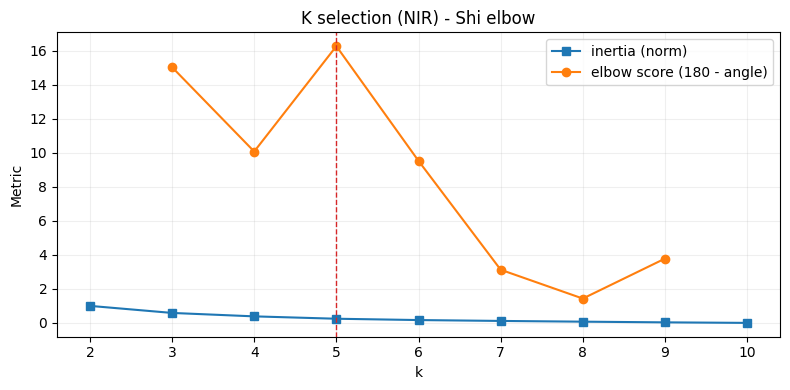

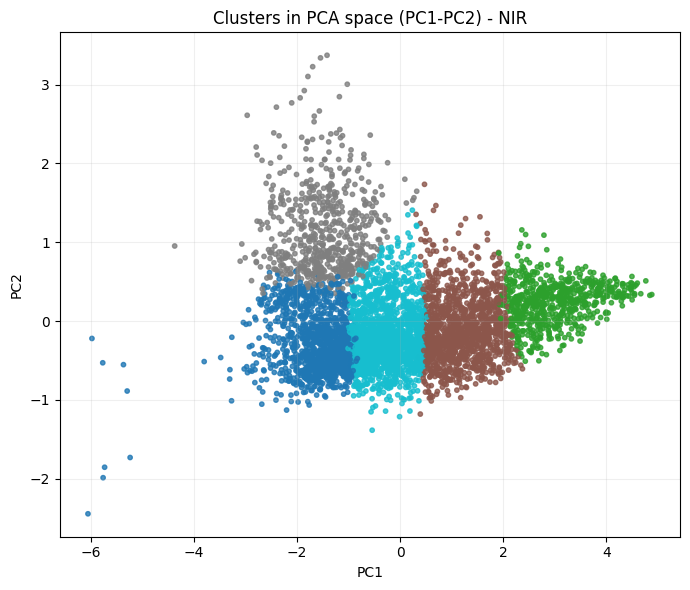

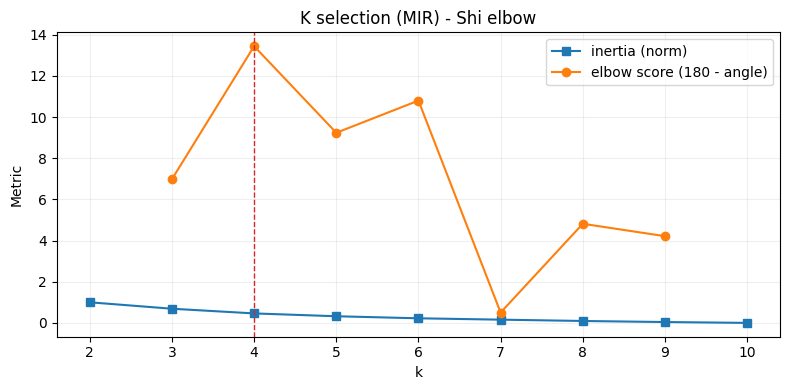

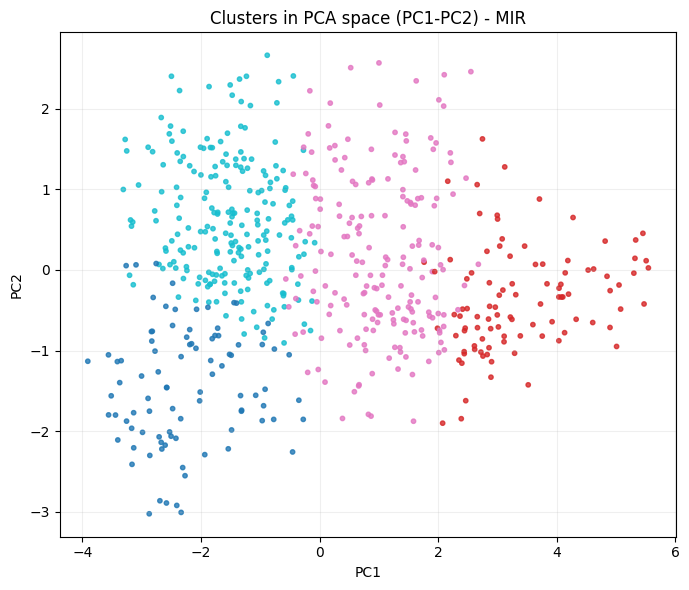

Stage 04 saved for NIR and MIR
Saved user report: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\04_user_report.txt


In [4]:
domain_figures = {}
domain_summaries = {}

for domain_name, domain_result in clustering_results.items():
    metrics_domain = domain_result['metrics_df']
    best_k_domain = domain_result['best_k']
    best_elbow_angle_domain = domain_result['best_elbow_angle_deg']
    cluster_labels_domain = domain_result['cluster_labels']
    X_domain = domain_result['X']
    assign_domain = domain_result['assign']

    plt.figure(figsize=(8, 4))
    plt.plot(metrics_domain['k'], metrics_domain['inertia_norm'], marker='s', label='inertia (norm)')
    plt.plot(metrics_domain['k'], metrics_domain['elbow_score'], marker='o', label='elbow score (180 - angle)')
    plt.axvline(best_k_domain, color='tab:red', ls='--', lw=1)
    plt.xlabel('k')
    plt.ylabel('Metric')
    plt.title(f'K selection ({domain_name.upper()}) - Shi elbow')
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    fig_k_domain = FIG_DIR / f'04_{domain_name}_k_selection.png'
    plt.savefig(fig_k_domain, dpi=180)
    plt.show()

    plot_scores_domain = pca_svd(X_domain, 2)['scores']
    plt.figure(figsize=(7, 6))
    plt.scatter(plot_scores_domain[:, 0], plot_scores_domain[:, 1], c=cluster_labels_domain, s=10, cmap='tab10', alpha=0.8)
    plt.title(f'Clusters in PCA space (PC1-PC2) - {domain_name.upper()}')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.grid(alpha=0.2)
    plt.tight_layout()
    fig_cluster_domain = FIG_DIR / f'04_{domain_name}_cluster_pca_scatter.png'
    plt.savefig(fig_cluster_domain, dpi=180)
    plt.show()

    domain_figures[domain_name] = {'fig_k': fig_k_domain, 'fig_cluster': fig_cluster_domain}
    domain_summaries[domain_name] = {
        'best_k': int(best_k_domain),
        'best_elbow_angle_deg': float(best_elbow_angle_domain) if np.isfinite(best_elbow_angle_domain) else None,
        'n_samples': int(len(assign_domain)),
    }

meta_payload = run_stamp('04_clustering', {
    'inputs': {
        'nir_clean': str(OUTPUT_DIR / '02_nir_clean.csv'),
        'nir_eda_scores': str(OUTPUT_DIR / '03_nir_pca_scores.csv'),
        'mir_clean': str(OUTPUT_DIR / '02_mir_clean.csv'),
        'mir_eda_scores': str(OUTPUT_DIR / '03_mir_pca_scores.csv'),
        'eda_metadata': str(OUTPUT_DIR / '03_eda_metadata.json'),
    },
    'selection': {
        'method': 'shi_2021_quantitative_elbow',
        'nir': domain_summaries['nir'],
        'mir': domain_summaries['mir'],
    },
    'timing_seconds': {'total': float(stage4_seconds)},
    'outputs': {
        'legacy_nir': {
            'k_metrics': str(OUTPUT_DIR / '04_k_selection_metrics.csv'),
            'cluster_assignments': str(OUTPUT_DIR / '04_cluster_assignments.csv'),
            'centroid_euclidean': str(OUTPUT_DIR / '04_centroid_euclidean.csv'),
            'centroid_pearson': str(OUTPUT_DIR / '04_centroid_pearson.csv'),
        },
        'nir': {
            'k_metrics': str(OUTPUT_DIR / '04_nir_k_selection_metrics.csv'),
            'cluster_assignments': str(OUTPUT_DIR / '04_nir_cluster_assignments.csv'),
            'centroid_euclidean': str(OUTPUT_DIR / '04_nir_centroid_euclidean.csv'),
            'centroid_pearson': str(OUTPUT_DIR / '04_nir_centroid_pearson.csv'),
            'fig_k': str(domain_figures['nir']['fig_k']),
            'fig_cluster': str(domain_figures['nir']['fig_cluster']),
        },
        'mir': {
            'k_metrics': str(OUTPUT_DIR / '04_mir_k_selection_metrics.csv'),
            'cluster_assignments': str(OUTPUT_DIR / '04_mir_cluster_assignments.csv'),
            'centroid_euclidean': str(OUTPUT_DIR / '04_mir_centroid_euclidean.csv'),
            'centroid_pearson': str(OUTPUT_DIR / '04_mir_centroid_pearson.csv'),
            'fig_k': str(domain_figures['mir']['fig_k']),
            'fig_cluster': str(domain_figures['mir']['fig_cluster']),
        },
    },
})
write_json(OUTPUT_DIR / '04_clustering_metadata.json', meta_payload)

report_lines = [
    'Stage 04 User Report',
    '===================',
    '',
    'Input files:',
    f'  - {OUTPUT_DIR / "02_nir_clean.csv"}',
    f'  - {OUTPUT_DIR / "03_nir_pca_scores.csv"}',
    f'  - {OUTPUT_DIR / "02_mir_clean.csv"}',
    f'  - {OUTPUT_DIR / "03_mir_pca_scores.csv"}',
    f'  - {OUTPUT_DIR / "03_eda_metadata.json"}',
    '',
    'Clustering summary by domain',
]

for domain_name in ['nir', 'mir']:
    domain_summary = domain_summaries[domain_name]
    report_lines.append(f'  - Domain: {domain_name.upper()}')
    report_lines.append(f"    Best K: {domain_summary['best_k']}")
    report_lines.append(
        f"    Best elbow angle (deg): {domain_summary['best_elbow_angle_deg']:.6f}"
        if domain_summary['best_elbow_angle_deg'] is not None
        else '    Best elbow angle (deg): not computable (fallback used)'
    )
    report_lines.append(f"    Number of samples clustered: {domain_summary['n_samples']}")

report_lines.extend([
    '',
    f'Runtime (seconds): {stage4_seconds:.2f}',
    '',
    'Main outputs - NIR (legacy compatible)',
    f'  - {OUTPUT_DIR / "04_k_selection_metrics.csv"}',
    f'  - {OUTPUT_DIR / "04_cluster_assignments.csv"}',
    f'  - {OUTPUT_DIR / "04_centroid_euclidean.csv"}',
    f'  - {OUTPUT_DIR / "04_centroid_pearson.csv"}',
    '',
    'Main outputs - NIR domain-specific',
    f'  - {OUTPUT_DIR / "04_nir_k_selection_metrics.csv"}',
    f'  - {OUTPUT_DIR / "04_nir_cluster_assignments.csv"}',
    f'  - {OUTPUT_DIR / "04_nir_centroid_euclidean.csv"}',
    f'  - {OUTPUT_DIR / "04_nir_centroid_pearson.csv"}',
    f'  - {domain_figures["nir"]["fig_k"]}',
    f'  - {domain_figures["nir"]["fig_cluster"]}',
    '',
    'Main outputs - MIR domain-specific',
    f'  - {OUTPUT_DIR / "04_mir_k_selection_metrics.csv"}',
    f'  - {OUTPUT_DIR / "04_mir_cluster_assignments.csv"}',
    f'  - {OUTPUT_DIR / "04_mir_centroid_euclidean.csv"}',
    f'  - {OUTPUT_DIR / "04_mir_centroid_pearson.csv"}',
    f'  - {domain_figures["mir"]["fig_k"]}',
    f'  - {domain_figures["mir"]["fig_cluster"]}',
    '',
    'Metadata and user report',
    f'  - {OUTPUT_DIR / "04_clustering_metadata.json"}',
    f'  - {OUTPUT_DIR / "04_user_report.txt"}',
])
out_report = OUTPUT_DIR / '04_user_report.txt'
out_report.write_text('\n'.join(report_lines), encoding='utf-8')

print('Stage 04 saved for NIR and MIR')
print(f'Saved user report: {out_report}')

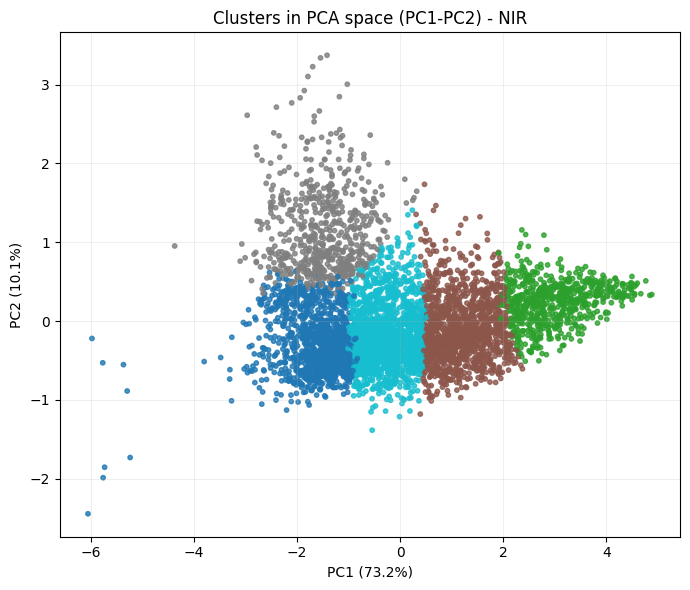

Saved updated PCA scatter for NIR: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\04_nir_cluster_pca_scatter.png


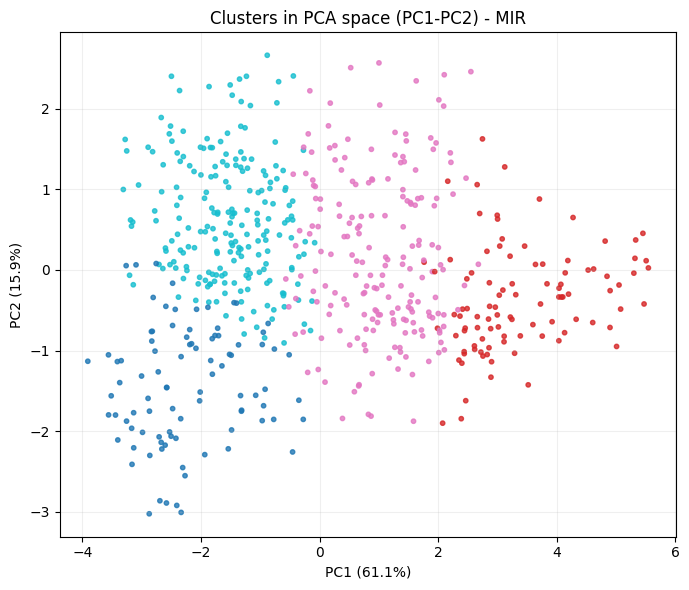

Saved updated PCA scatter for MIR: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\04_mir_cluster_pca_scatter.png


In [5]:
if 'clustering_results' not in globals():
    raise ValueError('clustering_results is not available. Run the clustering core cell first.')

for domain_name, domain_result in clustering_results.items():
    X_domain = domain_result['X']
    cluster_labels_domain = domain_result['cluster_labels']

    pca_plot_domain = pca_svd(X_domain, 2)
    plot_scores_domain = pca_plot_domain['scores']
    total_variance_domain = float(np.var(X_domain, axis=0, ddof=1).sum()) if X_domain.shape[0] > 1 else np.nan
    pc1_var_pct = float(100.0 * pca_plot_domain['explained_variance'][0] / total_variance_domain) if np.isfinite(total_variance_domain) and total_variance_domain > 0 else np.nan
    pc2_var_pct = float(100.0 * pca_plot_domain['explained_variance'][1] / total_variance_domain) if np.isfinite(total_variance_domain) and total_variance_domain > 0 and len(pca_plot_domain['explained_variance']) > 1 else np.nan

    plt.figure(figsize=(7, 6))
    plt.scatter(plot_scores_domain[:, 0], plot_scores_domain[:, 1], c=cluster_labels_domain, s=10, cmap='tab10', alpha=0.8)
    plt.title(f'Clusters in PCA space (PC1-PC2) - {domain_name.upper()}')
    plt.xlabel(f'PC1 ({pc1_var_pct:.1f}%)' if np.isfinite(pc1_var_pct) else 'PC1')
    plt.ylabel(f'PC2 ({pc2_var_pct:.1f}%)' if np.isfinite(pc2_var_pct) else 'PC2')
    plt.grid(alpha=0.2)
    plt.tight_layout()
    fig_cluster_domain = FIG_DIR / f'04_{domain_name}_cluster_pca_scatter.png'
    plt.savefig(fig_cluster_domain, dpi=180)
    plt.show()
    print(f'Saved updated PCA scatter for {domain_name.upper()}: {fig_cluster_domain}')